# Final Credit Risk Analysis

## Credit Risk Analytics — Predicting Credit Card Default

This notebook consolidates the project's analytical findings into a practical, research-oriented credit-risk decision framework. It independently reconstructs the selected Random Forest pipeline, recalculates its held-out performance, analyzes errors and risk segments, and documents considerations for responsible future use.

## 1. Introduction

The preceding notebooks covered data understanding, exploratory analysis, preprocessing, model evaluation, and interpretability. This final review brings those strands together without depending on variables created by earlier notebooks.

The analysis is a research exercise rather than a production lending system. Model outputs are decision-support signals; they are not automatic approval or rejection decisions, and the observed relationships do not establish causation.

## 2. Project Findings Consolidation

The source dataset contains 30,000 records and 23 predictors after excluding the identifier. The target is `default payment next month`; the observed class distribution is approximately 77.88% non-default and 22.12% default.

The earlier analysis examined demographics, credit limits, repayment history, billing amounts, and payment amounts. Preprocessing standardized category codes, used one-hot encoding for categorical and repayment-status variables, standardized age and credit limit, and applied Yeo-Johnson transformation followed by standardization to billing and payment amounts.

Models evaluated previously included a dummy baseline, logistic regression, decision tree, random forest, and gradient boosting. The selected Random Forest used a 0.55 probability threshold. Notebook 05 found that repayment-status and payment-amount variables were among the most influential descriptive signals, while illustrative probability segments showed increasing observed default rates from low to high predicted risk.

## 3. Environment, Dataset, and Reproducible Preparation

The notebook supports execution from the repository root or the `notebooks` directory. The first worksheet row is promoted to the actual header, and the category standardization matches the established modeling methodology.

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

CURRENT_DIRECTORY = Path.cwd()
PROJECT_ROOT = CURRENT_DIRECTORY.parent if CURRENT_DIRECTORY.name.lower() == "notebooks" else CURRENT_DIRECTORY
DATA_PATH = PROJECT_ROOT / "data" / "default of credit card clients.xls"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATA_PATH}")

In [10]:
df_raw = pd.read_excel(DATA_PATH)
df = df_raw.copy()
df.columns = df.iloc[0].astype(str).str.strip()
df = df.iloc[1:].reset_index(drop=True).apply(pd.to_numeric)

df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

target_column = "default payment next month"
print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
target_distribution = df[target_column].value_counts().sort_index()
target_summary = pd.DataFrame({
    "Customers": target_distribution,
    "Percentage": df[target_column].value_counts(normalize=True).sort_index().mul(100),
})
display(target_summary.round(2))

Dataset shape: (30000, 25)
Missing values: 0
Duplicate rows: 0


,Customers,Percentage
default payment next month,,
0,23364,77.88
1,6636,22.12


## 4. Model Performance Review

The pipeline below reproduces the exact selected Random Forest configuration. The stratified 80/20 split uses `random_state=42`. Preprocessing is fitted on training data only, and the established threshold of 0.55 is applied after test probabilities are generated. No threshold tuning is performed on the test set.

In [11]:
nominal_features = ["SEX", "EDUCATION", "MARRIAGE"]
repayment_features = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
billing_columns = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)]
amount_columns = billing_columns + payment_columns
demographic_features = ["AGE"]
financial_features = ["LIMIT_BAL"]
categorical_features = nominal_features + repayment_features
feature_columns = nominal_features + repayment_features + financial_features + amount_columns + demographic_features
required_columns = feature_columns + [target_column, "ID"]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

X = df[feature_columns].copy()
y = df[target_column].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

categorical_pipeline = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
standard_numeric_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])
amount_pipeline = Pipeline(steps=[
    ("power_transform", PowerTransformer(method="yeo-johnson", standardize=False)),
    ("scaler", StandardScaler()),
])
preprocessor = ColumnTransformer(transformers=[
    ("categorical", categorical_pipeline, categorical_features),
    ("standard_numeric", standard_numeric_pipeline, demographic_features + financial_features),
    ("amounts", amount_pipeline, amount_columns),
], remainder="drop")

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])
random_forest_model.fit(X_train, y_train)
y_test_probability = random_forest_model.predict_proba(X_test)[:, 1]
selected_threshold = 0.55
y_test_prediction = (y_test_probability >= selected_threshold).astype(int)

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_test_prediction),
    "Precision": precision_score(y_test, y_test_prediction, zero_division=0),
    "Recall": recall_score(y_test, y_test_prediction, zero_division=0),
    "F1-score": f1_score(y_test, y_test_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_probability),
})

print("Predictor count:", len(feature_columns))
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
display(test_metrics.to_frame("Recalculated score").round(4))
print("Classification report:")
print(classification_report(y_test, y_test_prediction, target_names=["No Default", "Default"], zero_division=0))
confusion = confusion_matrix(y_test, y_test_prediction)
display(pd.DataFrame(confusion, index=["Actual No Default", "Actual Default"], columns=["Predicted No Default", "Predicted Default"]))

Predictor count: 23
Training shape: (24000, 23)
Testing shape: (6000, 23)


,Recalculated score
Accuracy,0.8015
Precision,0.5532
Recall,0.5328
F1-score,0.5428
ROC-AUC,0.7762


Classification report:
              precision    recall  f1-score   support

  No Default       0.87      0.88      0.87      4673
     Default       0.55      0.53      0.54      1327

    accuracy                           0.80      6000
   macro avg       0.71      0.71      0.71      6000
weighted avg       0.80      0.80      0.80      6000



,Predicted No Default,Predicted Default
Actual No Default,4102,571
Actual Default,620,707


In [12]:
reference_metrics = pd.Series({
    "Accuracy": 0.8015,
    "Precision": 0.5532,
    "Recall": 0.5328,
    "F1-score": 0.5428,
    "ROC-AUC": 0.7762,
})
reference_confusion = np.array([[4102, 571], [620, 707]])
comparison = pd.DataFrame({
    "Recalculated": test_metrics,
    "Notebook 04 reference": reference_metrics,
})
comparison["Difference"] = comparison["Recalculated"] - comparison["Notebook 04 reference"]
print("Comparison with Notebook 04:")
display(comparison.round(4))
print("Confusion-matrix difference (recalculated minus reference):")
display(pd.DataFrame(confusion - reference_confusion, index=["Actual No Default", "Actual Default"], columns=["Predicted No Default", "Predicted Default"]))

Comparison with Notebook 04:


,Recalculated,Notebook 04 reference,Difference
Accuracy,0.8015,0.8015,0.0
Precision,0.5532,0.5532,0.0
Recall,0.5328,0.5328,-0.0
F1-score,0.5428,0.5428,0.0
ROC-AUC,0.7762,0.7762,0.0


Confusion-matrix difference (recalculated minus reference):


,Predicted No Default,Predicted Default
Actual No Default,0,0
Actual Default,0,0


## 5. Error Analysis

The four confusion-matrix outcomes have different implications:

- **True negative:** a non-default customer is not flagged; routine monitoring may be appropriate.
- **True positive:** a default customer is identified; the case may merit review or support prioritization.
- **False positive:** a non-default customer is flagged; unnecessary review, friction, or adverse treatment is possible.
- **False negative:** a default customer is missed; potential credit loss or missed early-support opportunity is possible.

These implications do not determine an optimal threshold because business costs, regulatory requirements, and customer-support policies were not supplied.

In [13]:
tn, fp, fn, tp = confusion.ravel()
error_summary = pd.DataFrame({
    "Outcome": ["True negative", "False positive", "False negative", "True positive"],
    "Count": [tn, fp, fn, tp],
    "Meaning": [
        "Actual non-default predicted as non-default",
        "Actual non-default predicted as default",
        "Actual default predicted as non-default",
        "Actual default predicted as default",
    ],
})
display(error_summary)
print(f"False-positive rate among actual non-default customers: {fp / (tn + fp):.4f}")
print(f"False-negative rate among actual default customers: {fn / (fn + tp):.4f}")

,Outcome,Count,Meaning
0,True negative,4102,Actual non-default predicted as non-default
1,False positive,571,Actual non-default predicted as default
2,False negative,620,Actual default predicted as non-default
3,True positive,707,Actual default predicted as default


False-positive rate among actual non-default customers: 0.1222
False-negative rate among actual default customers: 0.4672


## 6. Customer Risk Profile

The same illustrative boundaries used in Notebook 05 are retained: low predicted risk below 0.25, medium predicted risk from 0.25 to below 0.50, and high predicted risk at least 0.50. These boundaries are analytical assumptions, not universal banking standards. Segment labels describe predicted risk; actual default rates are observed afterward from held-out labels.

Risk-segment summary:


,Customers,Customer_percentage,Actual_defaults,Actual_default_rate,Average_predicted_probability
Risk segment,,,,,
Low predicted risk,1407,23.45,81,5.7569,0.2013
Medium predicted risk,3066,51.10,474,15.4599,0.3548
High predicted risk,1527,25.45,772,50.5566,0.7082


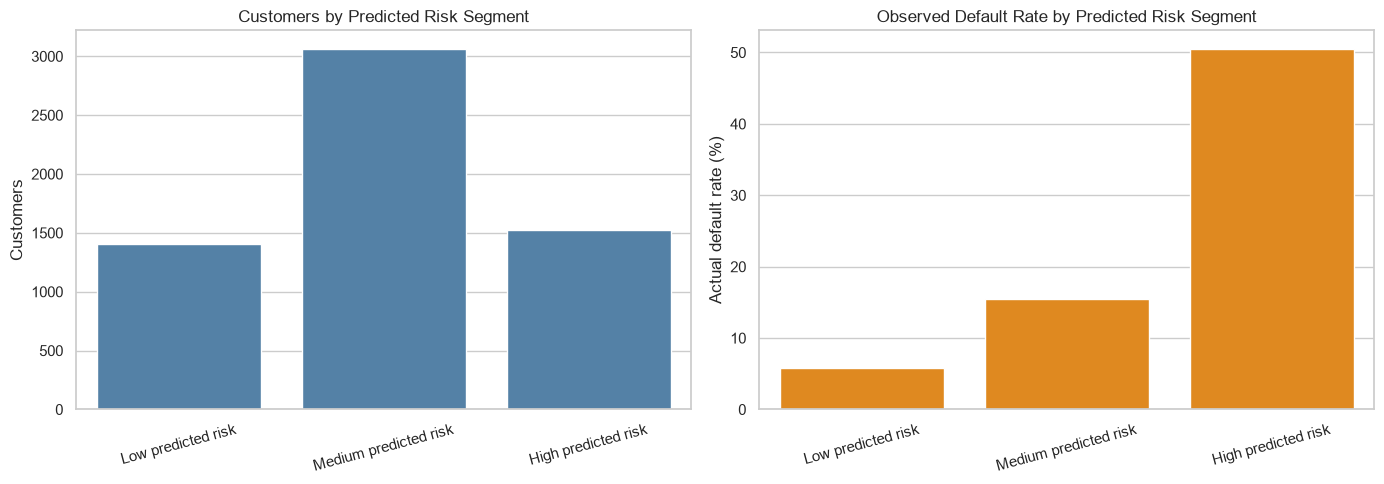

In [14]:
risk_bins = [-np.inf, 0.25, 0.50, np.inf]
risk_labels = ["Low predicted risk", "Medium predicted risk", "High predicted risk"]
risk_analysis = pd.DataFrame({
    "Predicted probability": y_test_probability,
    "Actual default": y_test.to_numpy(),
})
risk_analysis["Risk segment"] = pd.cut(risk_analysis["Predicted probability"], bins=risk_bins, labels=risk_labels, right=False)
segment_summary = risk_analysis.groupby("Risk segment", observed=False).agg(
    Customers=("Actual default", "size"),
    Customer_percentage=("Actual default", lambda values: len(values) / len(risk_analysis) * 100),
    Actual_defaults=("Actual default", "sum"),
    Actual_default_rate=("Actual default", "mean"),
    Average_predicted_probability=("Predicted probability", "mean"),
).reindex(risk_labels)
segment_summary["Actual_default_rate"] *= 100
print("Risk-segment summary:")
display(segment_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_data = segment_summary.reset_index()
sns.barplot(data=plot_data, x="Risk segment", y="Customers", ax=axes[0], color="steelblue")
axes[0].set_title("Customers by Predicted Risk Segment")
axes[0].set_xlabel("")
axes[0].set_ylabel("Customers")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=plot_data, x="Risk segment", y="Actual_default_rate", ax=axes[1], color="darkorange")
axes[1].set_title("Observed Default Rate by Predicted Risk Segment")
axes[1].set_xlabel("")
axes[1].set_ylabel("Actual default rate (%)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 7. Credit Risk Decision Framework

A research-oriented decision-support framework could use the segments as follows:

- **Low predicted risk:** continue routine monitoring and standard customer communication; do not treat the segment as a guarantee of repayment.
- **Medium predicted risk:** prioritize contextual review, verify current account information, and consider preventive customer-support outreach.
- **High predicted risk:** prioritize manual review and early-support or collections workflows subject to policy, human oversight, and applicable regulations.

The model should rank and prioritize cases rather than automatically approve, reject, price, or withdraw credit. Any operational threshold should be selected using documented business costs, validation data, fairness analysis, calibration assessment, and governance review.

## 8. Business Recommendations

1. Use repayment-history signals and payment behaviour as inputs to targeted monitoring, while avoiding causal interpretations.
2. Use the high-risk segment to prioritize human review and early customer-support interventions, not automatic adverse action.
3. Monitor false positives and false negatives separately because unnecessary intervention and missed defaults have different costs.
4. Review segment performance over time and across relevant customer groups before operational adoption.
5. Keep the model, preprocessing, threshold, and decision policy versioned together so that scores remain traceable.

## 9. Deployment Considerations

A future serving process would need to validate incoming schema, data types, category values, missingness, and plausible ranges before scoring. The fitted preprocessing steps must be applied identically to new records; ad hoc transformations outside the pipeline would create inconsistency.

Operational monitoring should track input drift, prediction-volume changes, segment distributions, delayed outcome metrics, and error rates. Periodic retraining should be triggered by documented evidence rather than an arbitrary schedule. Probability calibration should be evaluated before treating scores as likelihoods. Human review, audit logs, access controls, privacy safeguards, and a rollback process would also be required. This notebook does not implement an API or deployment application.

## 10. Project Limitations and Future Scope

- The dataset is historical and represents clients from Taiwan, limiting geographic and temporal generalization.
- The class imbalance makes accuracy alone inadequate for model assessment.
- The single stratified split does not establish performance under temporal or external validation.
- Probability calibration was not evaluated, so probabilities should be treated as model scores.
- Fairness and subgroup performance were not comprehensively measured.
- Correlated predictors complicate feature-importance interpretation.
- Production readiness would require governance, privacy and regulatory review, monitoring, documentation, and human oversight.

Future work should include temporal and external validation, calibration curves and calibration error measures, subgroup performance and fairness analysis, cost-sensitive threshold evaluation on validation data, drift monitoring, and a documented inference workflow.

## 11. Final Conclusion

The capstone establishes a complete research workflow from data quality assessment through model evaluation and interpretation. The reconstructed Random Forest provides a measurable ranking signal for default risk, and the risk segments show how model scores can support prioritization while preserving human judgment.

The appropriate conclusion is not that the model can make lending decisions automatically. Rather, it can serve as a documented starting point for risk monitoring and manual-review prioritization, subject to calibration, fairness, temporal validation, external validation, governance, and production controls.

In [15]:
print("Final analytical review summary")
print(test_metrics.round(4).to_string())
print("Confusion matrix:")
print(confusion)
print("Risk-segment actual default rates (%):")
print(segment_summary["Actual_default_rate"].round(2).to_string())
print("No calibration or fairness claim is made without dedicated evaluation.")

Final analytical review summary
Accuracy     0.8015
Precision    0.5532
Recall       0.5328
F1-score     0.5428
ROC-AUC      0.7762
Confusion matrix:
[[4102  571]
 [ 620  707]]
Risk-segment actual default rates (%):
Risk segment
Low predicted risk        5.76
Medium predicted risk    15.46
High predicted risk      50.56
No calibration or fairness claim is made without dedicated evaluation.
